In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

### Data

The **Criteo Uplift Prediction Dataset** contains data from a large-scale randomized online advertising experiment. The experiment was designed to study whether showing an advertisement to a user increases the likelihood that the user will visit a website or make a purchase.

The dataset includes information on whether a user was assigned to the treatment group, whether they were actually exposed to the advertisement, whether they visited the website, and whether they converted. It also contains 12 anonymized user-level features (f0–f11) that describe characteristics of the users.

The main variables are:

- **treatment** – indicates whether the user was assigned to the treatment group (1) or control group (0).
- **exposure** – indicates whether the treated user was actually exposed to the advertisement.
- **visit** – indicates whether the user visited the website.
- **conversion** – indicates whether the user completed a conversion, such as a purchase.
- **f0–f11** – anonymized user features that can be used to understand differences between users and predict their responses to advertising.

### Research Question

Given a fixed marketing budget, which customers should be targeted to maximize incremental conversions, rather than simply targeting customers who are most likely to purchase? 

### Project Objectives

**1.** Predict how much each customer’s behavior is expected to change because of the marketing treatment.

**2.** Target customers with the highest expected incremental conversion.

### Key Variables

- **Dependent Variable**: conversion
- **Independent / Treatment Variable**: treatment
- **Control Variables**: f0–f11

In [2]:
uplift_data = pd.read_csv('C:/Users/parva/Downloads/Capstone_2/Data/criteo-uplift-v2.1.csv')

In [3]:
uplift_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float64
 1   f1          float64
 2   f2          float64
 3   f3          float64
 4   f4          float64
 5   f5          float64
 6   f6          float64
 7   f7          float64
 8   f8          float64
 9   f9          float64
 10  f10         float64
 11  f11         float64
 12  treatment   int64  
 13  conversion  int64  
 14  visit       int64  
 15  exposure    int64  
dtypes: float64(12), int64(4)
memory usage: 1.7 GB


- f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11: feature values (dense, float)
- **treatment:** treatment group (1 = treated, 0 = control)
- **conversion:** whether a conversion occured for this user (binary, label)
- **visit:** whether a visit occured for this user (binary, label)
- **exposure:** treatment effect, whether the user has been effectively exposed (binary)

In [4]:
uplift_data.describe()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446582e+00,4.178923e+00,1.033884e+01,4.028513e+00,-4.155356e+00,5.101765e+00,3.933581e+00,1.602764e+01,5.333396e+00,-1.709672e-01,8.500001e-01,2.916680e-03,4.699200e-02,3.063122e-02
std,5.377464e+00,1.047557e-01,2.993161e-01,1.336645e+00,3.433081e-01,4.310974e-01,4.577914e+00,1.205248e+00,5.665958e-02,7.018975e+00,1.682288e-01,2.283277e-02,3.570713e-01,5.392748e-02,2.116217e-01,1.723164e-01
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011892e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2.674526e+01,1.634419e+01,9.051962e+00,4.679882e+00,2.112351e+01,4.115453e+00,2.944427e-01,1.199840e+01,3.971858e+00,7.529502e+01,6.473917e+00,-1.686792e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [5]:
uplift_data[['f0','f1','f2','f3','f4','f5','f6','f7','f8','f9','f10','f11']].describe()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446582e+00,4.178923e+00,1.033884e+01,4.028513e+00,-4.155356e+00,5.101765e+00,3.933581e+00,1.602764e+01,5.333396e+00,-1.709672e-01
std,5.377464e+00,1.047557e-01,2.993161e-01,1.336645e+00,3.433081e-01,4.310974e-01,4.577914e+00,1.205248e+00,5.665958e-02,7.018975e+00,1.682288e-01,2.283277e-02
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011892e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01
max,2.674526e+01,1.634419e+01,9.051962e+00,4.679882e+00,2.112351e+01,4.115453e+00,2.944427e-01,1.199840e+01,3.971858e+00,7.529502e+01,6.473917e+00,-1.686792e-01


In [6]:
uplift_data[['f0','f1','f2','f3','f4','f5','f6','f7','f8','f9','f10','f11']].dtypes

f0     float64
f1     float64
f2     float64
f3     float64
f4     float64
f5     float64
f6     float64
f7     float64
f8     float64
f9     float64
f10    float64
f11    float64
dtype: object

In [7]:
uplift_data.shape

(13979592, 16)

In [8]:
uplift_data.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [9]:
uplift_data.isnull().values.any()

np.False_

In [10]:
uplift_data.duplicated().sum()

np.int64(1259545)

- There is no unique user ID, and the 12 features have relatively few distinct values.
- Identical rows are therefore likely to represent different users with the same feature values, rather than data-entry errors.
- Dropping them would remove real observations. So, I decided not to discard them.

In [11]:
uplift_data['treatment'].value_counts()

treatment
1    11882655
0     2096937
Name: count, dtype: int64

In [12]:
uplift_data['treatment'].value_counts(normalize=True)

treatment
1    0.85
0    0.15
Name: proportion, dtype: float64

- The treatment split is 85% treated / 15% control, which is unusual because experiments typically have more balanced groups. Here, the control group is smaller.

In [13]:
uplift_data['conversion'].value_counts()

conversion
0    13938818
1       40774
Name: count, dtype: int64

In [14]:
uplift_data['visit'].value_counts()

visit
0    13322663
1      656929
Name: count, dtype: int64

In [15]:
uplift_data['exposure'].value_counts()

exposure
0    13551380
1      428212
Name: count, dtype: int64

In [16]:
print(uplift_data['treatment'].unique())
print(uplift_data['conversion'].unique())
print(uplift_data['visit'].unique())
print(uplift_data['exposure'].unique())

[1 0]
[0 1]
[0 1]
[0 1]


In [17]:
uplift_data.groupby('treatment')[['conversion', 'visit', 'exposure']].mean()

,conversion,visit,exposure
treatment,,,
0,0.001938,0.038201,0.000000
1,0.003089,0.048543,0.036037


## Data Cleaning

- I downcast the data types to reduce memory usage. The four label columns are 0/1, and the features don't need 64-bit precision. This roughly halves memory usage and speeds up the analysis below.

In [18]:
binary_cols = ['treatment', 'conversion', 'visit', 'exposure']
feature_cols = [f'f{i}' for i in range(12)]

uplift_data[binary_cols] = uplift_data[binary_cols].astype('int8')
uplift_data[feature_cols] = uplift_data[feature_cols].astype('float32')

uplift_data.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float32
 1   f1          float32
 2   f2          float32
 3   f3          float32
 4   f4          float32
 5   f5          float32
 6   f6          float32
 7   f7          float32
 8   f8          float32
 9   f9          float32
 10  f10         float32
 11  f11         float32
 12  treatment   int8   
 13  conversion  int8   
 14  visit       int8   
 15  exposure    int8   
dtypes: float32(12), int8(4)
memory usage: 693.3 MB


- Downcasting reduced memory usage from ~1.7 GB to ~693 MB (roughly 60% smaller) with no loss of information.
- The label columns are exactly 0/1, and float32 provides enough precision for these features.

**Integrity checks**
- I check that exposure occurs only in the treated group and examine how visits and conversions relate.


In [19]:
pd.crosstab(uplift_data['treatment'], uplift_data['exposure'])

exposure,0,1
treatment,,
0,2096937,0
1,11454443,428212


- All 428,212 exposed users are in the treatment group, while the control group has zero exposure. This is exactly how it should be!

In [20]:
pd.crosstab(uplift_data['visit'], uplift_data['conversion'])

conversion,0,1
visit,,
0,13322663,0
1,616155,40774


- All 40,774 conversions occur among users who visit, with zero conversions among non-visitors.

**Quantify class imbalance in the target** 
- Uplift conversion rates are typically very low, so it is important to check how common conversions are in the data.


In [21]:
uplift_data['conversion'].value_counts(normalize=True)

conversion
0    0.997083
1    0.002917
Name: proportion, dtype: float64

**Inspect feature tails for outliers** 
- I use extended percentiles to check for unusually large or small values.

In [22]:
uplift_data[feature_cols].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
)

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446583e+00,4.178923e+00,1.033884e+01,4.028512e+00,-4.155355e+00,5.101766e+00,3.933581e+00,1.602764e+01,5.333397e+00,-1.709673e-01
std,5.459194e+00,7.458533e-01,4.915796e-01,1.327135e+00,1.096672e+00,4.154038e-01,4.537465e+00,1.305157e+00,8.450601e-02,6.740313e+00,5.931901e-01,2.821619e-02
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011891e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00
1%,1.261636e+01,1.005965e+01,8.214383e+00,-1.733228e+00,1.028053e+01,2.230907e+00,-1.777727e+01,4.833815e+00,3.751603e+00,1.319006e+01,5.300375e+00,-2.673502e-01
5%,1.261636e+01,1.005965e+01,8.214383e+00,9.738408e-01,1.028053e+01,3.013064e+00,-1.335345e+01,4.833815e+00,3.806309e+00,1.319006e+01,5.300375e+00,-1.686792e-01
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01
95%,2.631187e+01,1.005965e+01,9.004230e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,6.045297e+00,3.971858e+00,3.371255e+01,5.300375e+00,-1.686792e-01


In [23]:
uplift_data.groupby('treatment')[['conversion', 'visit', 'exposure']].mean()

,conversion,visit,exposure
treatment,,,
0,0.001938,0.038201,0.000000
1,0.003089,0.048543,0.036037


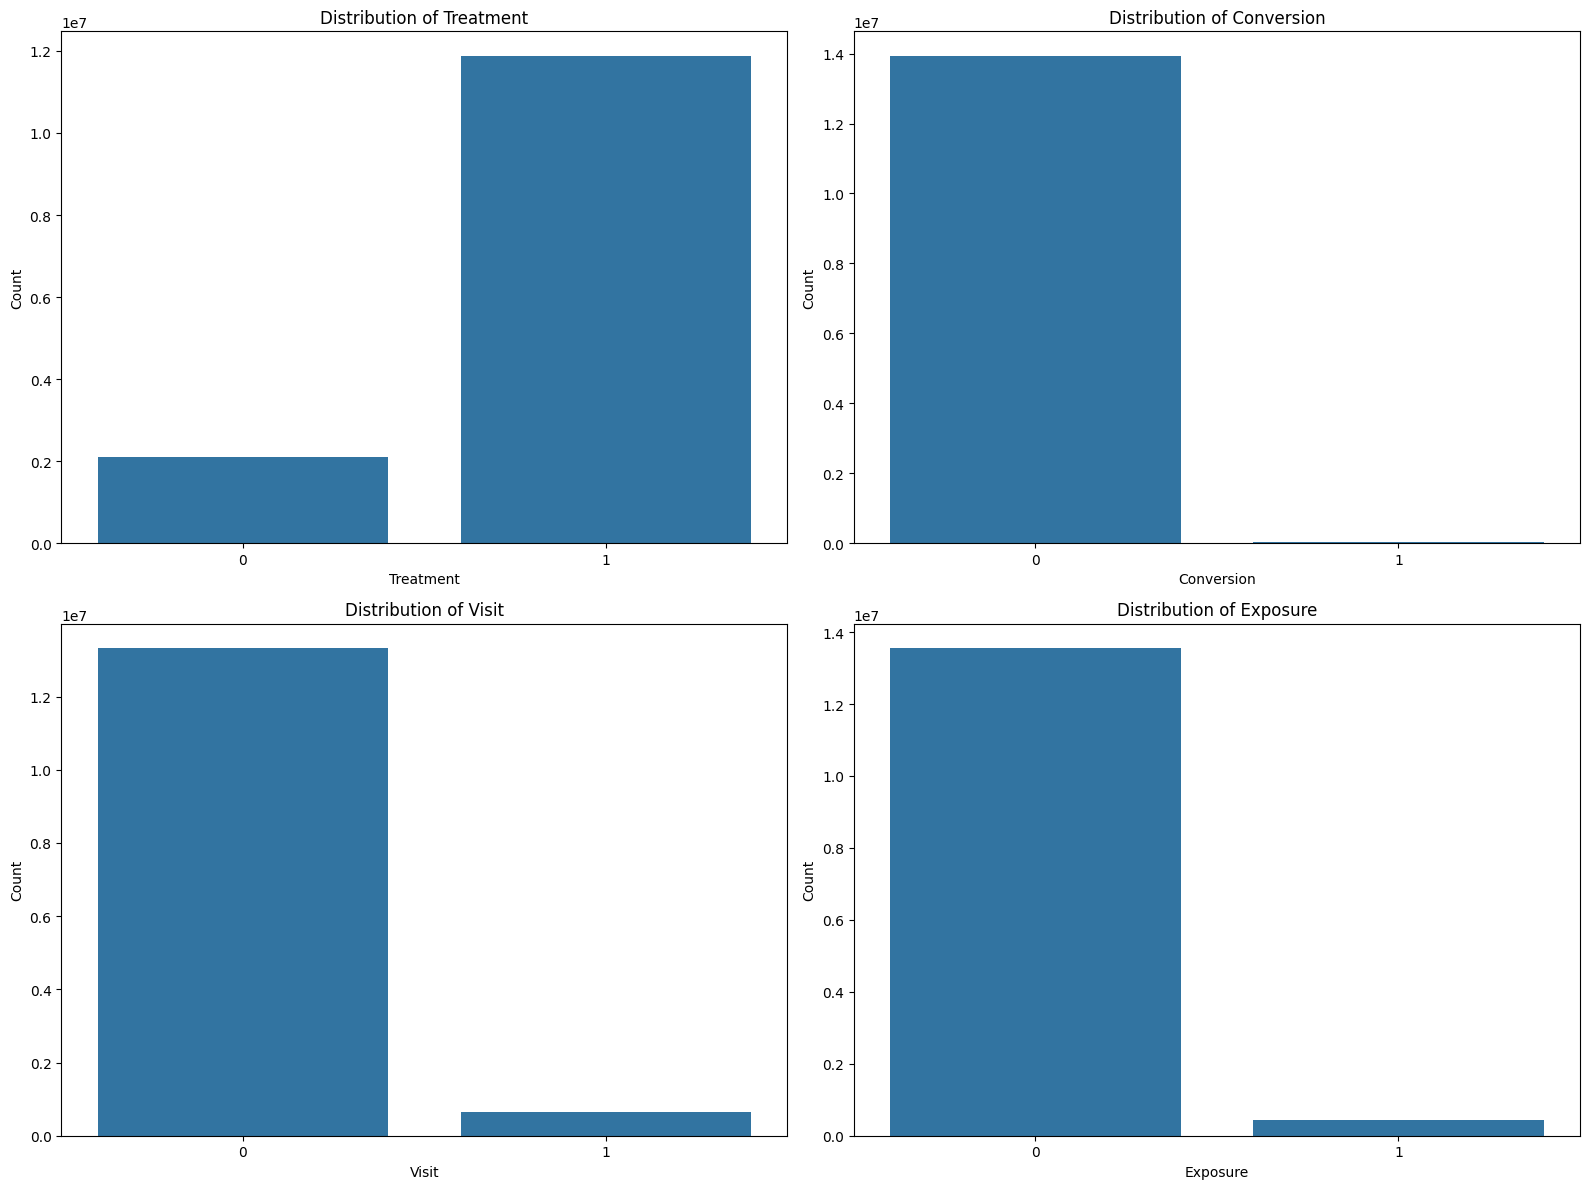

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(data=uplift_data, x='treatment', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Treatment')
axes[0, 0].set_xlabel('Treatment')
axes[0, 0].set_ylabel('Count')

sns.countplot(data=uplift_data, x='conversion', ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Conversion')
axes[0, 1].set_xlabel('Conversion')
axes[0, 1].set_ylabel('Count')

sns.countplot(data=uplift_data, x='visit', ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Visit')
axes[1, 0].set_xlabel('Visit')
axes[1, 0].set_ylabel('Count')

sns.countplot(data=uplift_data, x='exposure', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Exposure')
axes[1, 1].set_xlabel('Exposure')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

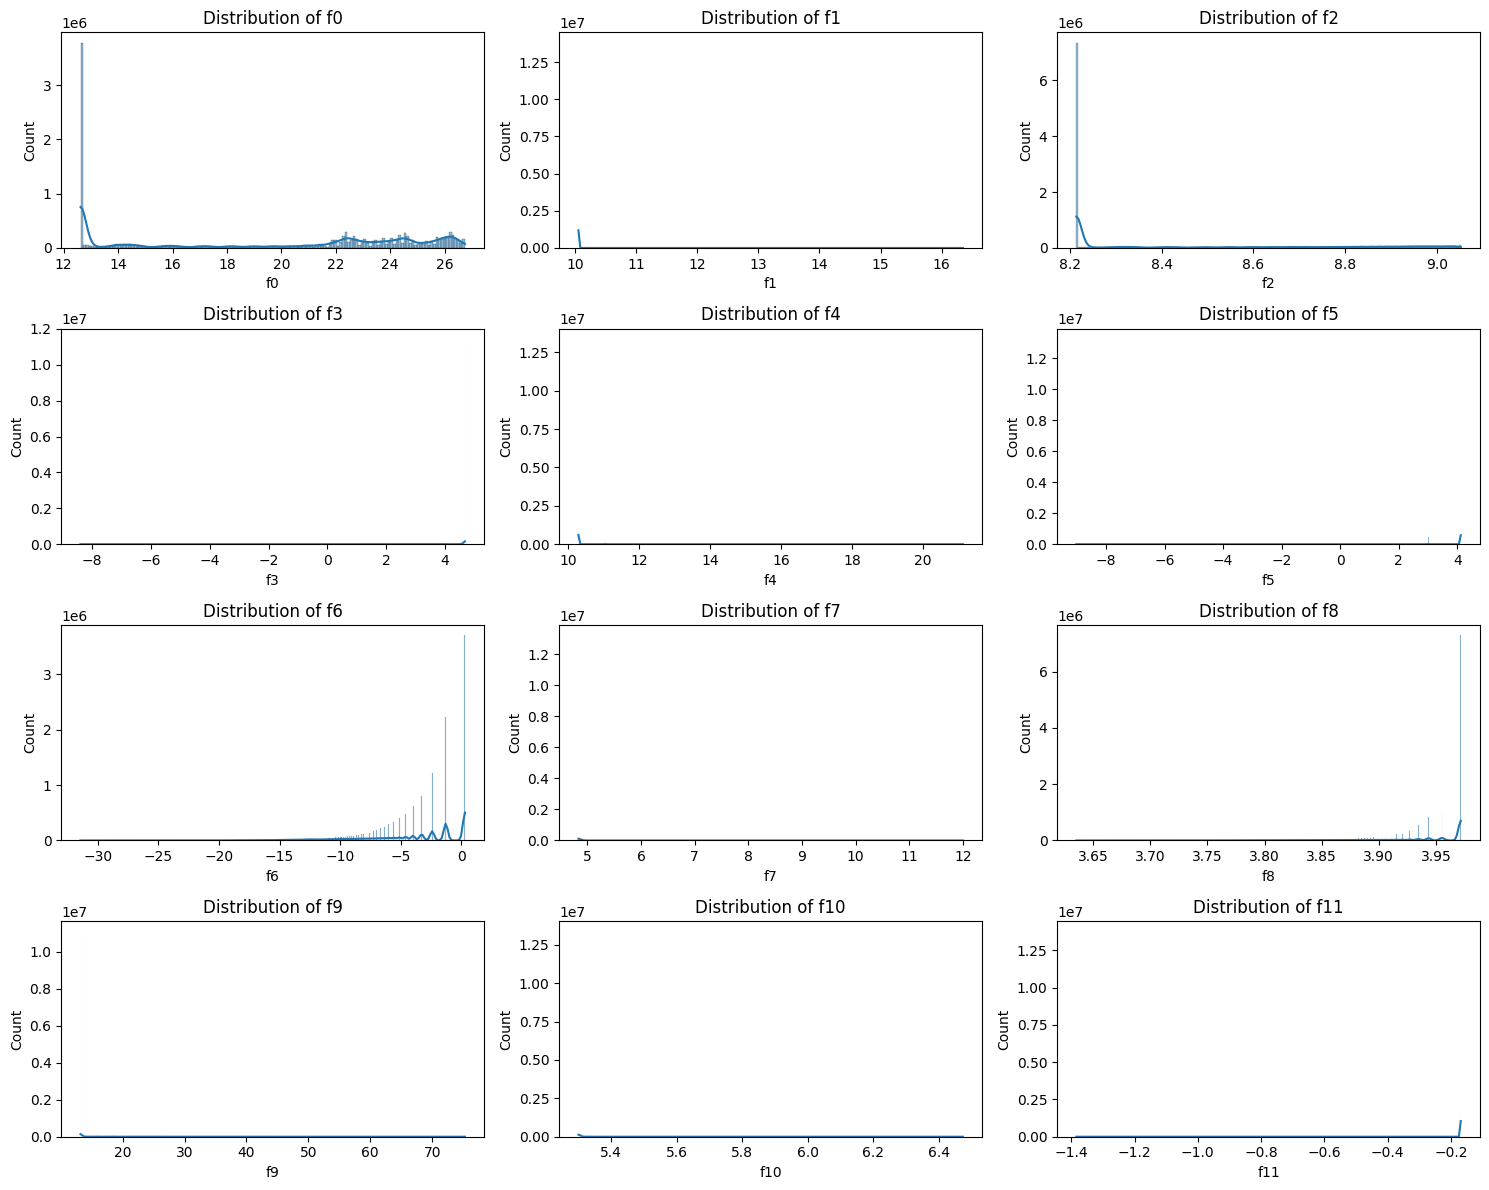

In [25]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))

sns.histplot(uplift_data['f0'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of f0', fontsize=12)
axes[0, 0].set_xlabel('f0')
axes[0, 0].set_ylabel('Count')

sns.histplot(uplift_data['f1'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Distribution of f1', fontsize=12)
axes[0, 1].set_xlabel('f1')
axes[0, 1].set_ylabel('Count')

sns.histplot(uplift_data['f2'], kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Distribution of f2', fontsize=12)
axes[0, 2].set_xlabel('f2')
axes[0, 2].set_ylabel('Count')

sns.histplot(uplift_data['f3'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Distribution of f3', fontsize=12)
axes[1, 0].set_xlabel('f3')
axes[1, 0].set_ylabel('Count')

sns.histplot(uplift_data['f4'], kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Distribution of f4', fontsize=12)
axes[1, 1].set_xlabel('f4')
axes[1, 1].set_ylabel('Count')

sns.histplot(uplift_data['f5'], kde=True, ax=axes[1, 2])
axes[1, 2].set_title('Distribution of f5', fontsize=12)
axes[1, 2].set_xlabel('f5')
axes[1, 2].set_ylabel('Count')

sns.histplot(uplift_data['f6'], kde=True, ax=axes[2, 0])
axes[2, 0].set_title('Distribution of f6', fontsize=12)
axes[2, 0].set_xlabel('f6')
axes[2, 0].set_ylabel('Count')

sns.histplot(uplift_data['f7'], kde=True, ax=axes[2, 1])
axes[2, 1].set_title('Distribution of f7', fontsize=12)
axes[2, 1].set_xlabel('f7')
axes[2, 1].set_ylabel('Count')

sns.histplot(uplift_data['f8'], kde=True, ax=axes[2, 2])
axes[2, 2].set_title('Distribution of f8', fontsize=12)
axes[2, 2].set_xlabel('f8')
axes[2, 2].set_ylabel('Count')

sns.histplot(uplift_data['f9'], kde=True, ax=axes[3, 0])
axes[3, 0].set_title('Distribution of f9', fontsize=12)
axes[3, 0].set_xlabel('f9')
axes[3, 0].set_ylabel('Count')

sns.histplot(uplift_data['f10'], kde=True, ax=axes[3, 1])
axes[3, 1].set_title('Distribution of f10', fontsize=12)
axes[3, 1].set_xlabel('f10')
axes[3, 1].set_ylabel('Count')

sns.histplot(uplift_data['f11'], kde=True, ax=axes[3, 2])
axes[3, 2].set_title('Distribution of f11', fontsize=12)
axes[3, 2].set_xlabel('f11')
axes[3, 2].set_ylabel('Count')

plt.tight_layout()
plt.show()

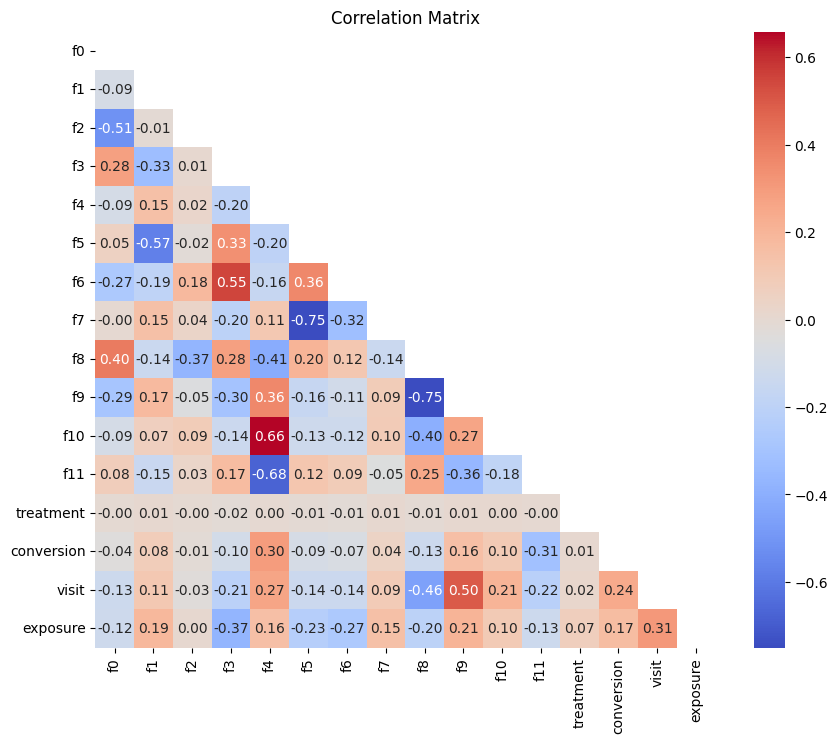

In [26]:
plt.figure(figsize=(10, 8))

corr = uplift_data.corr(numeric_only=True)

# Mask the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

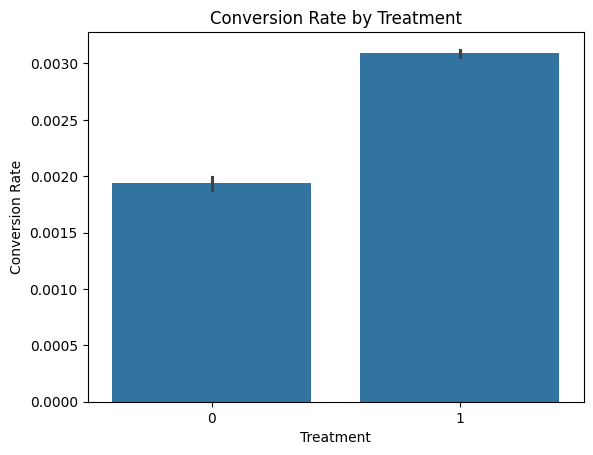

In [27]:
sns.barplot(data=uplift_data, x='treatment', y='conversion')

plt.title('Conversion Rate by Treatment')
plt.xlabel('Treatment')
plt.ylabel('Conversion Rate')
plt.show()

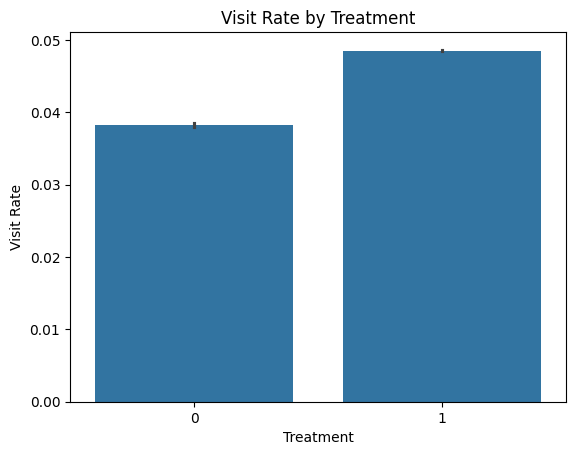

In [28]:
sns.barplot(data=uplift_data, x='treatment', y='visit')

plt.title('Visit Rate by Treatment')
plt.xlabel('Treatment')
plt.ylabel('Visit Rate')
plt.show()

- Below I calculate the average visit/conversion rates for the treatment and control groups, then subtract the control rates from the treatment rates to measure the overall uplift from the marketing campaign.

In [33]:
# Average rates for the control group
control = uplift_data[uplift_data['treatment'] == 0][['visit', 'conversion']].mean()

# Average rates for the treatment group
treated = uplift_data[uplift_data['treatment'] == 1][['visit', 'conversion']].mean()

# Difference between treatment and control
uplift = treated - control

print('Control rates:', control)
#print(control)

print('---')
print('Treatment rates:', treated)
#print(treated)

print('---')
print('Uplift (treated - control):', uplift)
#print(uplift)

Control rates: visit         0.038201
conversion    0.001938
dtype: float64
---
Treatment rates: visit         0.048543
conversion    0.003089
dtype: float64
---
Uplift (treated - control): visit         0.010342
conversion    0.001152
dtype: float64


**Interpreting the uplift (ATE).** 
- Treatment increases the visit rate from 3.82% to 4.85% (+1.03 pp, or approx. 27% relative lift) and the conversion rate from 0.194% to 0.309% (+0.12 pp, or approx. 59% relative lift).
- So, the campaign has a small absolute effect on a rare outcome. 

Now, I'll conduct the **Proportion z-test.** The Null and the alternative hupothesis are as follows:

- H_0: Treatment and control groups have the same conversion (visit) rate.
- H_1: Treatment and control groups have different conversion (visit) rates.

- If p < 0.05 then statistically significant difference, i.e, we reject the Null.
- If p >= 0.05 then not statistically significant, i.e., we fail to reject the Null.

In [34]:
from statsmodels.stats.proportion import proportions_ztest

table = uplift_data.groupby('treatment')['conversion'].agg(['sum', 'count'])

z, p = proportions_ztest(table['sum'], table['count'])

print("Conversion p-value:", p)

Conversion p-value: 7.30826328583868e-179


- There is very strong statistical evidence that the treatment and control groups have different conversion rates.

In [35]:
table = uplift_data.groupby('treatment')['visit'].agg(['sum', 'count'])

z, p = proportions_ztest(table['sum'], table['count'])

print("Visit p-value:", p)

Visit p-value: 0.0


- There is very strong statistical evidence that the treatment and control groups have different visit rates.

- Now, I compare the average characteristics of the treatment and control groups to check whether the groups are balanced.

In [36]:
balance = uplift_data.groupby('treatment')[feature_cols].mean().T
balance.columns = ['control', 'treated']
balance['diff'] = balance['treated'] - balance['control']
balance

,control,treated,diff
f0,19.651705,19.614754,-0.036951
f1,10.067935,10.070336,0.002401
f2,8.448174,8.446301,-0.001872
f3,4.232821,4.169412,-0.063409
f4,10.336526,10.339245,0.002719
f5,4.039339,4.026602,-0.012736
f6,-3.999880,-4.182793,-0.182913
f7,5.080284,5.105555,0.025271
f8,3.934652,3.933392,-0.001260
f9,15.886252,16.052589,0.166337


- The groups appear quite well balanced overall. Below I'll conduct a standardized mean differences (SMD) to check if groups are reasonably balanced before treatment.

In [37]:
# Calculate means for each group
means = uplift_data.groupby('treatment')[feature_cols].mean()

# Calculate standard deviations for each group
stds = uplift_data.groupby('treatment')[feature_cols].std()

# Calculate pooled standard deviation
pooled_std = np.sqrt((stds.loc[0]**2 + stds.loc[1]**2) / 2)

# Calculate SMD
smd = (means.loc[1] - means.loc[0]) / pooled_std

print(smd)

f0    -0.006866
f1     0.023995
f2    -0.006243
f3    -0.048836
f4     0.007964
f5    -0.030557
f6    -0.040448
f7     0.021269
f8    -0.022432
f9     0.024001
f10    0.010562
f11   -0.005159
dtype: float32


- Since all of your SMDs are well below 0.1, the treatment and control groups appear well balanced across these features.

#### Do people who convert have different characteristics from people who don't convert?

In [38]:
uplift_data.groupby('conversion')[feature_cols].mean().T

conversion,0,1
f0,19.631342,15.844798
f1,10.069506,10.230936
f2,8.446812,8.368136
f3,4.186458,1.603213
f4,10.333293,12.234429
f5,4.030535,3.337044
f6,-4.137540,-10.245744
f7,5.098913,6.076578
f8,3.933981,3.796801
f9,15.968325,36.304489


**Feature differences** 
- Several features show noticeable differences between converters and non-converters, especially
  - f0 (19.6 vs 15.8),
  - f3 (4.19 vs 1.60),
  - f4 (10.3 vs 12.2)
  - f6 (−4.14 vs −10.25), and
  - f9 (16.0 vs 36.3).
- This suggests the features contain useful information for predicting who is likely to convert. 

- Converters and non-converters have different average feature values.


#### Among people assigned to treatment, how many actually saw the treatment, and do people who were exposed have a different conversion rate?

In [40]:
treated = uplift_data[uplift_data['treatment'] == 1]
print('Exposure rate among treated:', treated['exposure'].mean())
print()
print(treated.groupby('exposure')['conversion'].mean())

Exposure rate among treated: 0.036036727482199896

exposure
0    0.001194
1    0.053784
Name: conversion, dtype: float64


- Only **3.6%** of treated users were exposed. Among treated users, the conversion rate was **5.38%** for those exposed compared with **0.12%** for those not exposed.
- This large difference suggests a strong association between exposure and conversion.

**Important caveat:** 
- I treat this comparison as *associational, not causal*.
- Exposure is not randomized, so the 5.38% vs 0.12% gap may reflect both the ad's effect and differences between users.
- I therefore do not interpret this as exposure causing a ~45× lift. I also keep `exposure` out of the feature set.

#### Whether visiting the website is associated with a higher likelihood of conversion?

In [41]:
visitors = uplift_data[uplift_data['visit'] == 1]
print('Conversion rate, all users:', uplift_data['conversion'].mean())
print('Conversion rate, visitors: ', visitors['conversion'].mean())

Conversion rate, all users: 0.002916680257907384
Conversion rate, visitors:  0.06206759025709019


- Visitors had a much higher conversion rate than the overall user population, suggesting a strong association between visiting and conversion.

## Sampling & Saving the Cleaned Data

**Stratified sample** 
- I use a stratified sample for faster iteration while preserving the treatment ratio.

In [29]:
sample = uplift_data.groupby('treatment', group_keys=False).apply(
    lambda x: x.sample(frac=0.05, random_state=42)
)
sample.shape

C:\Users\parva\AppData\Local\Temp\ipykernel_9160\2176030203.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = uplift_data.groupby('treatment', group_keys=False).apply(


(698980, 16)

In [30]:
uplift_data.to_parquet('uplift_clean.parquet')

#### I now plot boxplots to see which features have different distributions between people who converted and those who did not convert.

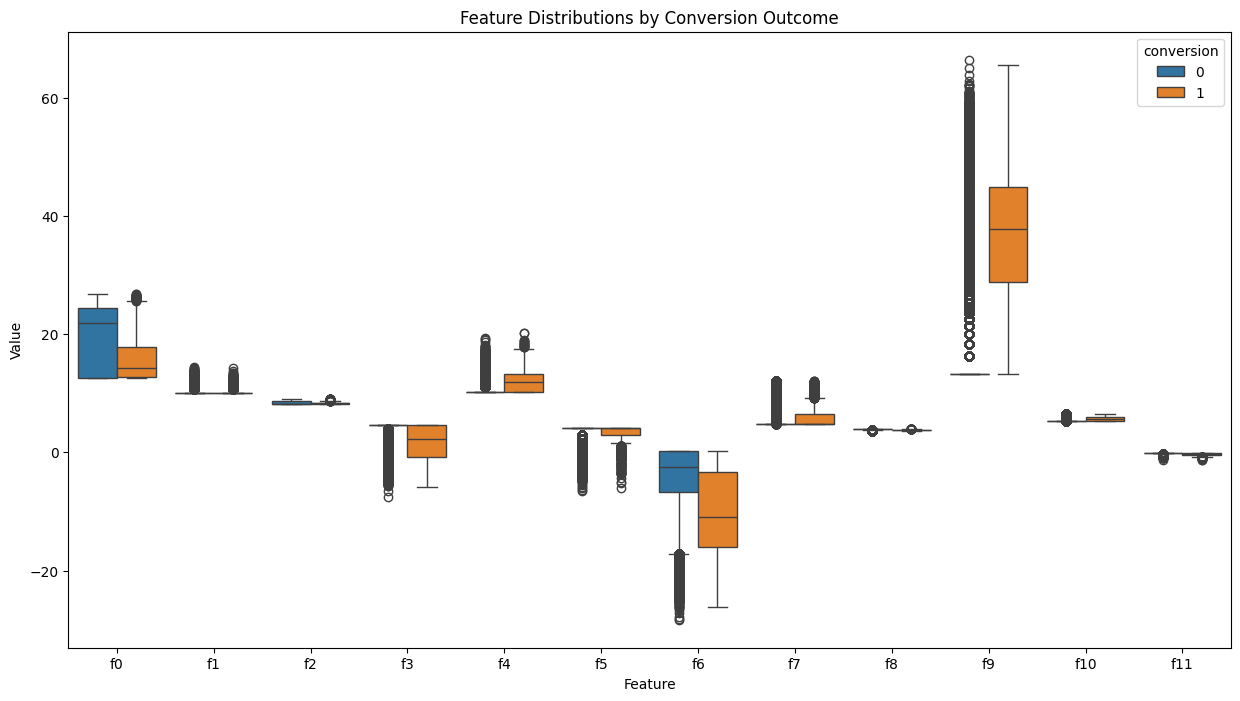

In [39]:
melted = sample.melt(id_vars='conversion', value_vars=feature_cols)

plt.figure(figsize=(15, 8))
sns.boxplot(data=melted, x='variable', y='value', hue='conversion')
plt.title('Feature Distributions by Conversion Outcome')
plt.xlabel('Feature')
plt.ylabel('Value')
plt.show()

**Boxplots by conversion outcome (on the 5% sample)**
- I use boxplots to compare the features between converters and non-converters.
- f3, f6, and f9 show the clearest separation, consistent with the grouped means above.
- Features with heavily overlapping boxes show less difference between the two groups.